In [181]:
import pandas as pd

In [182]:
df = pd.read_csv('/content/Zomato Restaurant reviews.csv')

In [183]:
display(df)

,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0
...,...,...,...,...,...,...,...
9995,Chinese Pavilion,Abhishek Mahajan,Madhumathi Mahajan Well to start with nice cou...,3,"53 Reviews , 54 Followers",6/5/2016 0:08,0
9996,Chinese Pavilion,Sharad Agrawal,This place has never disappointed us.. The foo...,4.5,"2 Reviews , 53 Followers",6/4/2016 22:01,0
9997,Chinese Pavilion,Ramandeep,"Bad rating is mainly because of ""Chicken Bone ...",1.5,"65 Reviews , 423 Followers",6/3/2016 10:37,3
9998,Chinese Pavilion,Nayana Shanbhag,I personally love and prefer Chinese Food. Had...,4,"13 Reviews , 144 Followers",5/31/2016 17:22,0


In [184]:
def count_null_values(df):
    null_count = df.isnull().sum()
    result = pd.DataFrame({
        "null_count": null_count,
        "null_percentage": (null_count / len(df) * 100).round(2)
    })
    return result.sort_values(by="null_count", ascending=False)

count_null_values(df)

,null_count,null_percentage
Review,45,0.45
Reviewer,38,0.38
Rating,38,0.38
Time,38,0.38
Metadata,38,0.38
Restaurant,0,0.00
Pictures,0,0.00


In [185]:
df[df["Rating"].isnull()]

,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
8777,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8778,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8779,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8780,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8781,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8782,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8783,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8784,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8785,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0
8786,American Wild Wings,NaN,NaN,NaN,NaN,NaN,0


In [186]:
df = df.dropna(subset=["Rating", "Review"]).reset_index(drop=True)

In [187]:
df.head()

,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0


In [188]:
def count_null_values(df):
    null_count = df.isnull().sum()
    result = pd.DataFrame({
        "null_count": null_count,
        "null_percentage": (null_count / len(df) * 100).round(2)
    })
    return result.sort_values(by="null_count", ascending=False)

count_null_values(df)

,null_count,null_percentage
Restaurant,0,0.0
Reviewer,0,0.0
Review,0,0.0
Rating,0,0.0
Metadata,0,0.0
Time,0,0.0
Pictures,0,0.0


In [189]:
df["Rating"].value_counts().sort_index()

,count
Rating,
1,1735
1.5,9
2,684
2.5,19
3,1192
3.5,47
4,2373
4.5,69
5,3826


In [190]:
import pandas as pd

df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")

df["Label"] = pd.Series(pd.NA, index=df.index, dtype="string")

df.loc[df["Rating"].between(1, 3.5), "Label"] = "negative"
df.loc[df["Rating"].between(4, 5), "Label"] = "positive"

print(df["Label"].value_counts(dropna=False))

Label
positive    6268
negative    3686
<NA>           1
Name: count, dtype: Int64


In [191]:
df.sample()['Review'].values

array(['late delivery cold food'], dtype=object)

In [192]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9955 entries, 0 to 9954
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Restaurant  9955 non-null   object 
 1   Reviewer    9955 non-null   object 
 2   Review      9955 non-null   object 
 3   Rating      9954 non-null   float64
 4   Metadata    9955 non-null   object 
 5   Time        9955 non-null   object 
 6   Pictures    9955 non-null   int64  
 7   Label       9954 non-null   string 
dtypes: float64(1), int64(1), object(5), string(1)
memory usage: 622.3+ KB


In [193]:
df = df.dropna(subset=["Rating", "Review"]).reset_index(drop=True)

In [194]:
df['Review'] = df['Review'].str.lower()

In [195]:
df.head()

,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures,Label
0,Beyond Flavours,Rusha Chakraborty,"the ambience was good, food was quite good . h...",5.0,"1 Review , 2 Followers",5/25/2019 15:54,0,positive
1,Beyond Flavours,Anusha Tirumalaneedi,ambience is too good for a pleasant evening. s...,5.0,"3 Reviews , 2 Followers",5/25/2019 14:20,0,positive
2,Beyond Flavours,Ashok Shekhawat,a must try.. great food great ambience. thnx f...,5.0,"2 Reviews , 3 Followers",5/24/2019 22:54,0,positive
3,Beyond Flavours,Swapnil Sarkar,soumen das and arun was a great guy. only beca...,5.0,"1 Review , 1 Follower",5/24/2019 22:11,0,positive
4,Beyond Flavours,Dileep,food is good.we ordered kodi drumsticks and ba...,5.0,"3 Reviews , 2 Followers",5/24/2019 21:37,0,positive


In [196]:
df.columns = df.columns.str.lower()

In [197]:
# Remove trailing and leading whitespaces from the 'clean_comment' column
df['review'] = df['review'].str.strip()

# Verify the transformation by checking for any remaining trailing whitespaces
df['review'].apply(lambda x: x.endswith(' ') or x.startswith(' ')).sum()

np.int64(0)

In [198]:

# Identify comments containing URLs
url_pattern = r'http[s]?://(?:[a-zA-Z]|[0-9]|[$-_@.&+]|[!*\(\),]|(?:%[0-9a-fA-F][0-9a-fA-F]))+'
comments_with_urls = df[df['review'].str.contains(url_pattern, regex=True)]

# Display the comments containing URLs
comments_with_urls.head()


,restaurant,reviewer,review,rating,metadata,time,pictures,label
371,Shah Ghouse Hotel & Restaurant,DieEating,"to sum it up - ""amazingly delicious"".\n\nwe or...",4.0,"27 Reviews , 42 Followers",3/31/2019 22:30,3,positive
2596,Tiki Shack,HungerDaddy,"tiki shak, gachibowli - hyderabad\n\nthe gachi...",4.0,"81 Reviews , 140 Followers",2/8/2019 13:42,5,positive


In [199]:

# Identify comments containing new line characters
comments_with_newline = df[df['review'].str.contains('\n')]

# Display the comments containing new line characters
display(comments_with_newline)

,restaurant,reviewer,review,rating,metadata,time,pictures,label
0,Beyond Flavours,Rusha Chakraborty,"the ambience was good, food was quite good . h...",5.0,"1 Review , 2 Followers",5/25/2019 15:54,0,positive
5,Beyond Flavours,Nagabhavani K,"ambiance is good, service is good, food is apr...",5.0,1 Review,5/24/2019 15:22,0,positive
16,Beyond Flavours,Shubham Jaiswal,came here for lunch and the food was good and ...,4.0,"30 Reviews , 34 Followers",5/22/2019 19:54,8,positive
23,Beyond Flavours,Tony,we had our farewell feast here recently enjoye...,5.0,"8 Reviews , 25 Followers",5/21/2019 5:43,0,positive
29,Beyond Flavours,Ppck2412,food is descent enough. desert options were al...,4.0,"3 Reviews , 3 Followers",5/20/2019 12:11,0,positive
...,...,...,...,...,...,...,...,...
9948,Chinese Pavilion,Shiladitya Chaudhury,chinese pavilion in banjara hills was the firs...,1.5,"6 Reviews , 3 Followers",6/5/2016 10:49,0,negative
9949,Chinese Pavilion,Abhishek Mahajan,madhumathi mahajan well to start with nice cou...,3.0,"53 Reviews , 54 Followers",6/5/2016 0:08,0,negative
9951,Chinese Pavilion,Ramandeep,"bad rating is mainly because of ""chicken bone ...",1.5,"65 Reviews , 423 Followers",6/3/2016 10:37,3,negative
9952,Chinese Pavilion,Nayana Shanbhag,i personally love and prefer chinese food. had...,4.0,"13 Reviews , 144 Followers",5/31/2016 17:22,0,positive


In [200]:
import pandas as pd

# Thay newline và các ký tự xuống dòng bằng dấu cách
df["review"] = df["review"].str.replace(r"[\r\n]+", " ", regex=True)

# Chuẩn hóa khoảng trắng liên tiếp và loại bỏ khoảng trắng đầu/cuối
df["review"] = df["review"].str.replace(r"\s+", " ", regex=True).str.strip()

In [201]:
# Đếm số review còn chứa ký tự xuống dòng
remaining = df["review"].str.contains(r"[\r\n]", na=False).sum()

print("Số review còn ký tự xuống dòng:", remaining)

Số review còn ký tự xuống dòng: 0


<Axes: xlabel='label', ylabel='count'>

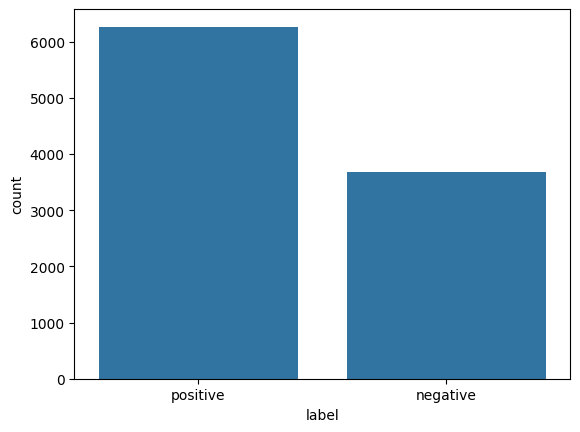

In [202]:

import seaborn as sns
import matplotlib.pyplot as plt
# distribution of classes

sns.countplot(data=df,x="label")

In [203]:
# frequency distribution of sentiments
df['label'].value_counts(normalize=True).mul(100).round(2)

,proportion
label,
positive,62.97
negative,37.03


<Axes: xlabel='rating', ylabel='count'>

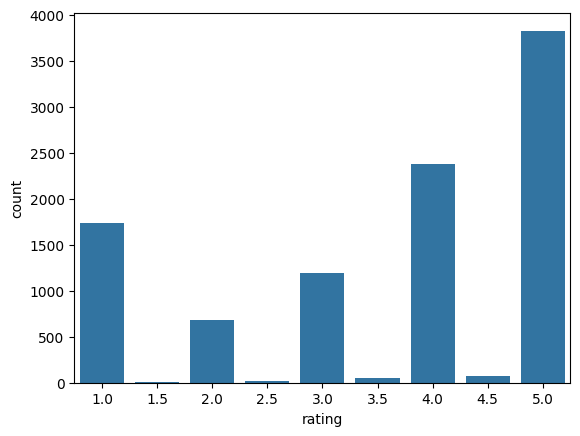

In [204]:
sns.countplot(data=df,x="rating")

In [205]:
df['rating'].value_counts(normalize=True).mul(100).round(2)

,proportion
rating,
5.0,38.44
4.0,23.84
1.0,17.43
3.0,11.98
2.0,6.87
4.5,0.69
3.5,0.47
2.5,0.19
1.5,0.09


In [206]:
df['word_count'] = df['review'].apply(lambda x: len(x.split()))

In [207]:
df.head()

,restaurant,reviewer,review,rating,metadata,time,pictures,label,word_count
0,Beyond Flavours,Rusha Chakraborty,"the ambience was good, food was quite good . h...",5.0,"1 Review , 2 Followers",5/25/2019 15:54,0,positive,41
1,Beyond Flavours,Anusha Tirumalaneedi,ambience is too good for a pleasant evening. s...,5.0,"3 Reviews , 2 Followers",5/25/2019 14:20,0,positive,27
2,Beyond Flavours,Ashok Shekhawat,a must try.. great food great ambience. thnx f...,5.0,"2 Reviews , 3 Followers",5/24/2019 22:54,0,positive,31
3,Beyond Flavours,Swapnil Sarkar,soumen das and arun was a great guy. only beca...,5.0,"1 Review , 1 Follower",5/24/2019 22:11,0,positive,28
4,Beyond Flavours,Dileep,food is good.we ordered kodi drumsticks and ba...,5.0,"3 Reviews , 2 Followers",5/24/2019 21:37,0,positive,27


In [208]:
df['word_count'].describe()

,word_count
count,9954.000000
mean,50.173297
std,60.786767
min,1.000000
25%,24.000000
50%,34.000000
75%,58.000000
max,964.000000


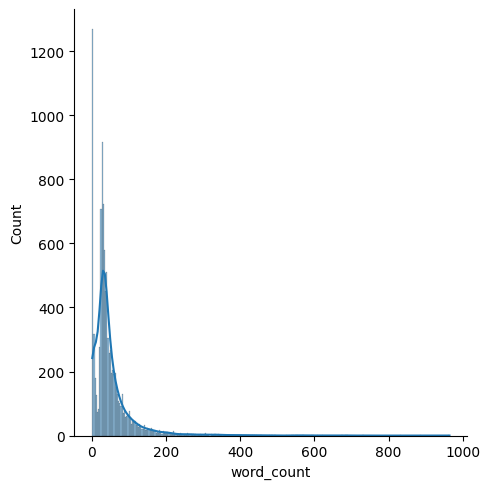

In [209]:
sns.displot(df['word_count'], kde=True)

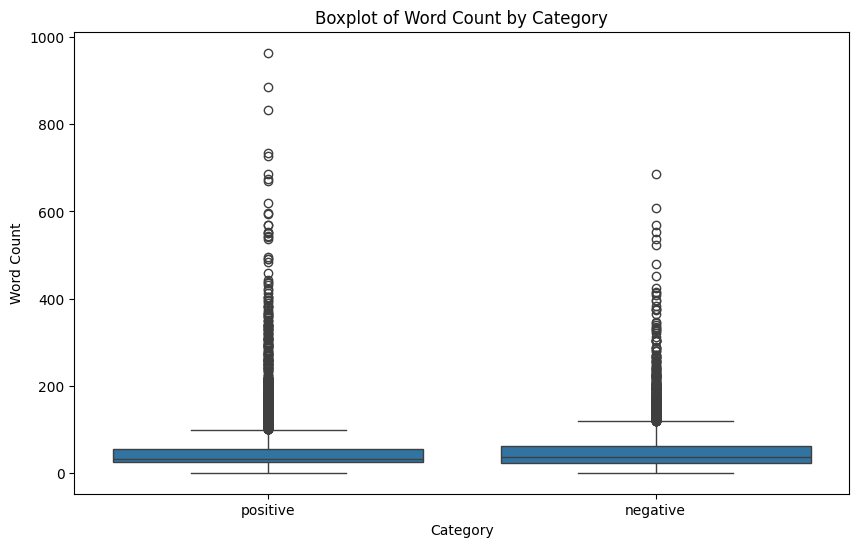

In [210]:
# Create a boxplot for the 'wordcount' column categorized by 'category'
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='label', y='word_count')
plt.title('Boxplot of Word Count by Category')
plt.xlabel('Category')
plt.ylabel('Word Count')
plt.show()


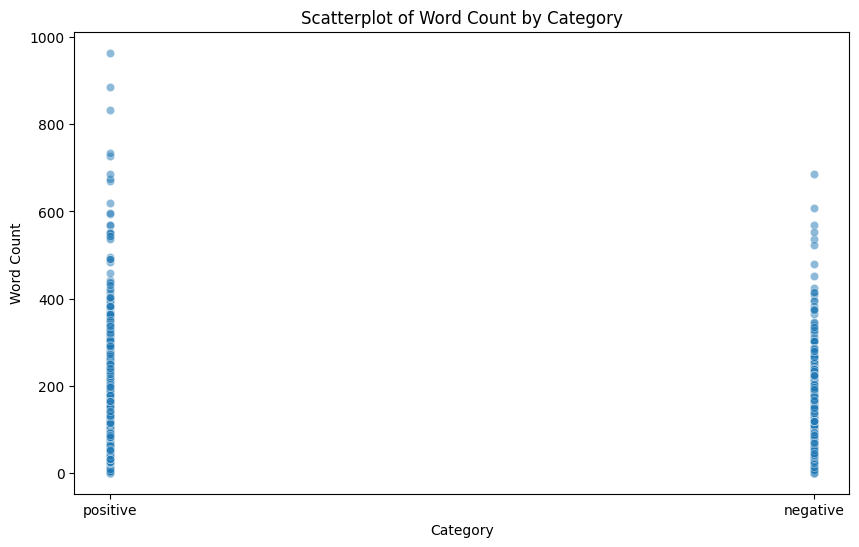

In [211]:
# Create a scatterplot between 'category' and 'wordcount'
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='label', y='word_count', alpha=0.5)
plt.title('Scatterplot of Word Count by Category')
plt.xlabel('Category')
plt.ylabel('Word Count')
plt.show()

<Axes: xlabel='label', ylabel='word_count'>

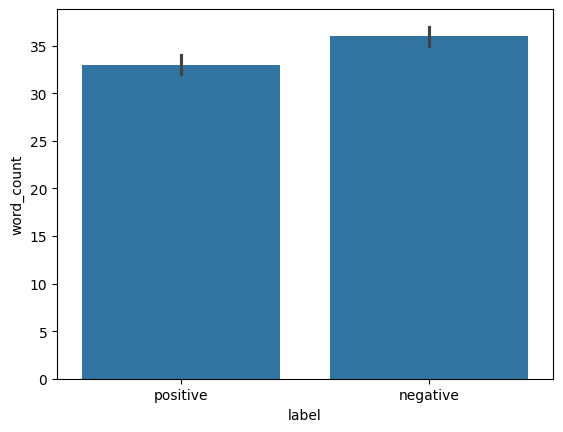

In [212]:
# median word counts among sentiments

sns.barplot(df,x='label',y='word_count',estimator='median')

In [213]:
!pip install nltk

In [214]:
from nltk.corpus import stopwords

# Download NLTK stopwords if not already downloaded
import nltk
nltk.download('stopwords')

# Define the list of English stopwords
stop_words = set(stopwords.words('english'))

# Create a new column 'num_stop_words' by counting the number of stopwords in each comment
df['num_stop_words'] = df['review'].apply(lambda x: len([word for word in x.split() if word in stop_words]))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


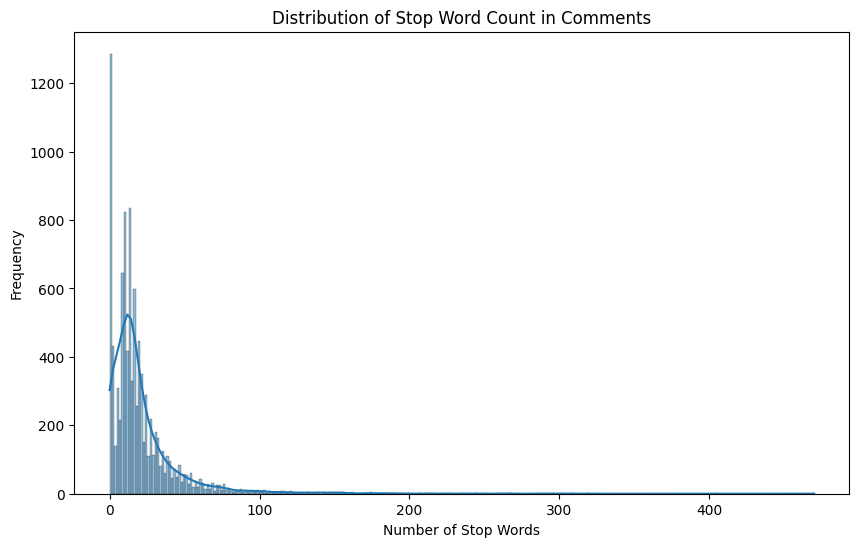

In [215]:
# Create a distribution plot (displot) for the 'num_stop_words' column
plt.figure(figsize=(10, 6))
sns.histplot(df['num_stop_words'], kde=True)
plt.title('Distribution of Stop Word Count in Comments')
plt.xlabel('Number of Stop Words')
plt.ylabel('Frequency')
plt.show()

In [216]:
df['num_chars'] = df['review'].apply(len)

df.head()

,restaurant,reviewer,review,rating,metadata,time,pictures,label,word_count,num_stop_words,num_chars
0,Beyond Flavours,Rusha Chakraborty,"the ambience was good, food was quite good . h...",5.0,"1 Review , 2 Followers",5/25/2019 15:54,0,positive,41,14,222
1,Beyond Flavours,Anusha Tirumalaneedi,ambience is too good for a pleasant evening. s...,5.0,"3 Reviews , 2 Followers",5/25/2019 14:20,0,positive,27,12,144
2,Beyond Flavours,Ashok Shekhawat,a must try.. great food great ambience. thnx f...,5.0,"2 Reviews , 3 Followers",5/24/2019 22:54,0,positive,31,11,189
3,Beyond Flavours,Swapnil Sarkar,soumen das and arun was a great guy. only beca...,5.0,"1 Review , 1 Follower",5/24/2019 22:11,0,positive,28,13,148
4,Beyond Flavours,Dileep,food is good.we ordered kodi drumsticks and ba...,5.0,"3 Reviews , 2 Followers",5/24/2019 21:37,0,positive,27,9,160


In [217]:
df['num_chars'].describe()

,num_chars
count,9954.000000
mean,279.216496
std,337.379392
min,1.000000
25%,144.000000
50%,189.000000
75%,321.000000
max,5212.000000


In [218]:
from collections import Counter

# Combine all comments into one large string
all_text = ' '.join(df['review'])

# Count the frequency of each character
char_frequency = Counter(all_text)

# Convert the character frequency into a DataFrame for better display
char_frequency_df = pd.DataFrame(char_frequency.items(), columns=['character', 'frequency']).sort_values(by='frequency', ascending=False)



In [219]:
char_frequency_df['character'].values

array([' ', 'e', 'a', 't', 'o', 'i', 's', 'n', 'r', 'h', 'd', 'l', 'c',
       'u', 'm', '.', 'f', 'y', 'w', 'g', 'p', 'b', 'v', 'k', ',', 'z',
       'x', 'j', "'", '!', 'q', '5', '-', '/', ':', '0', ')', '4', '1',
       '3', '(', '2', '’', '&', '"', '#', '6', '?', '*', '9', '️', '7',
       '=', '8', '😍', '👍', '+', ';', '😊', '😋', '👌', '@', '❤', '%', '⭐',
       '_', '🌟', '“', '”', '🏻', '😀', '•', '▪', '😁', '➖', '😂', '😉', '🤩',
       '👎', '🍖', '~', '👏', '😃', '♥', '✌', '>', '₹', '|', '🙂', '‘',
       '\u200d', '😅', '😒', '☺', '[', '🤘', ']', 'é', '☹', '😄', '😎', '😜',
       '🤗', '😡', '🙄', '😐', '🤮', '🤣', '♀', '🙏', 'à', '🙆', '–', '💰', '—',
       '<', '🔥', '🍗', '☆', '😛', '🍺', '🤤', '🌶', '😑', '💯', '🤟', '💕', '🙈',
       '🍻', '🤔', '😇', 'ä', '🏼', '😳', '🍔', '🍰', '🍚', 'ñ', '😠', '÷', '🍹',
       '🔹', '😬', '🏽', '😘', '🖕', '🍱', '🥘', '💓', '😌', '✓', '🤭', '🍸', '🙌',
       '😪', '😕', '︎', '🥂', '🍩', '🥰', '🤪', '🍝', '☕', '…', '⃣', '😝', '🍽',
       '🤝', '😭', '🤷', '❣', '💃', '♂', '🐔', '🍕', '🍨', '🐟', '🍄', '🐪', '🐫

/tmp/ipykernel_3297/735349222.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_25_bigrams_df, x='count', y='bigram', palette='magma')


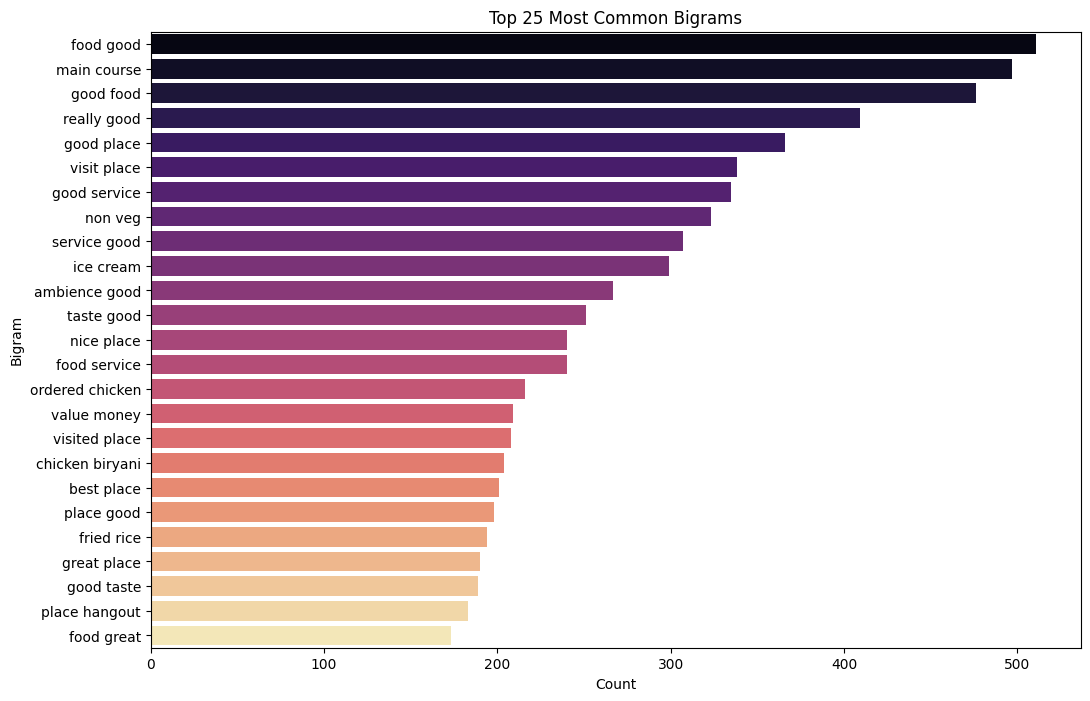

In [220]:
from sklearn.feature_extraction.text import CountVectorizer

# Create a function to extract the top 25 bigrams
def get_top_ngrams(corpus, n=None):
    vec = CountVectorizer(ngram_range=(2, 2), stop_words='english').fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)
    return words_freq[:n]

# Get the top 25 bigrams
top_25_bigrams = get_top_ngrams(df['review'], 25)

# Convert the bigrams into a DataFrame for plotting
top_25_bigrams_df = pd.DataFrame(top_25_bigrams, columns=['bigram', 'count'])

# Plot the countplot for the top 25 bigrams
plt.figure(figsize=(12, 8))
sns.barplot(data=top_25_bigrams_df, x='count', y='bigram', palette='magma')
plt.title('Top 25 Most Common Bigrams')
plt.xlabel('Count')
plt.ylabel('Bigram')
plt.show()



/tmp/ipykernel_3297/559995602.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_25_trigrams_df, x='count', y='trigram', palette='coolwarm')


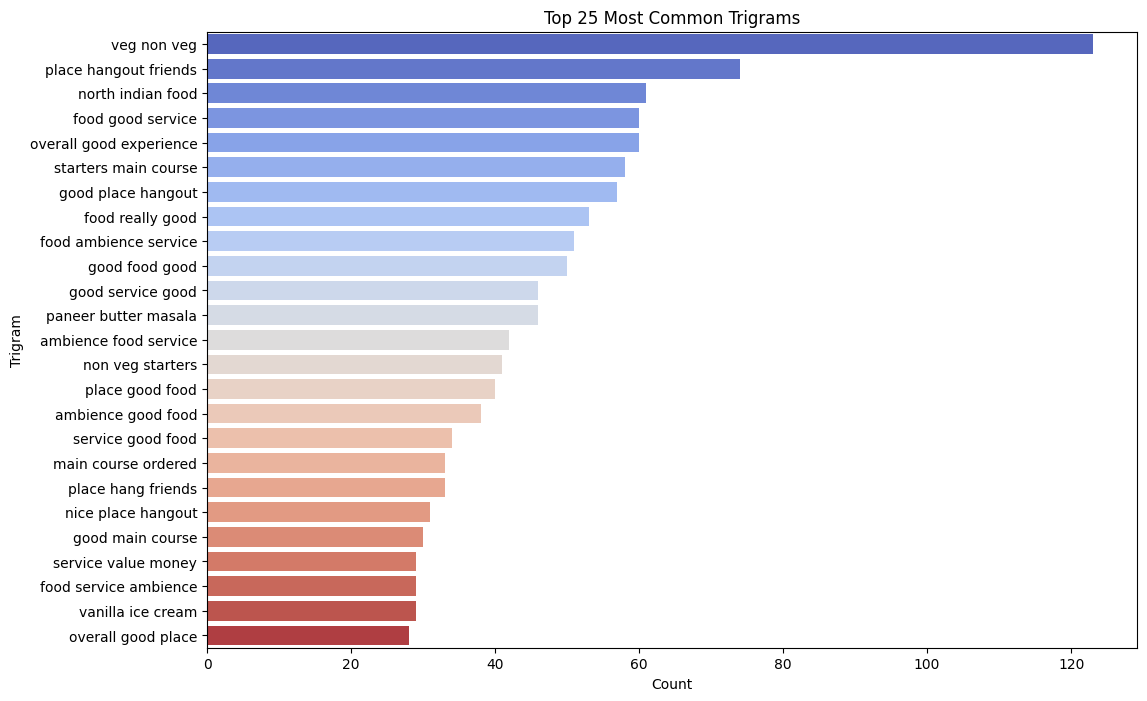

In [221]:
# Create a function to extract the top 25 trigrams
def get_top_trigrams(corpus, n=None):
    vec = CountVectorizer(ngram_range=(3, 3), stop_words='english').fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)
    return words_freq[:n]

# Get the top 25 trigrams
top_25_trigrams = get_top_trigrams(df['review'], 25)

# Convert the trigrams into a DataFrame for plotting
top_25_trigrams_df = pd.DataFrame(top_25_trigrams, columns=['trigram', 'count'])

# Plot the countplot for the top 25 trigrams
plt.figure(figsize=(12, 8))
sns.barplot(data=top_25_trigrams_df, x='count', y='trigram', palette='coolwarm')
plt.title('Top 25 Most Common Trigrams')
plt.xlabel('Count')
plt.ylabel('Trigram')
plt.show()

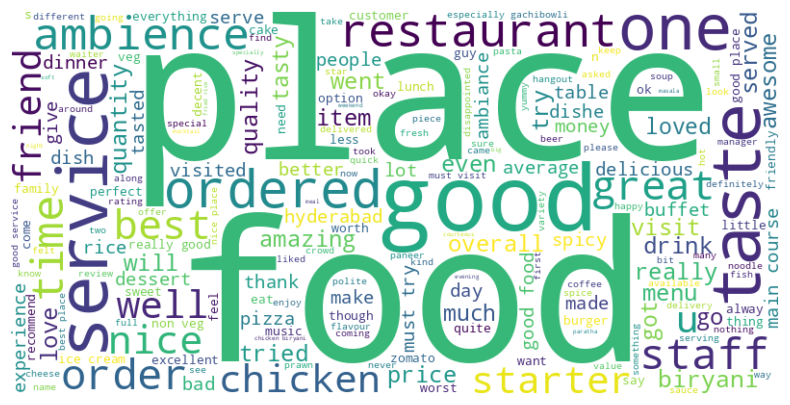

In [222]:

from wordcloud import WordCloud
import matplotlib.pyplot as plt

def plot_word_cloud(text):
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(' '.join(text))
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off")
    plt.show()

plot_word_cloud(df['review'])

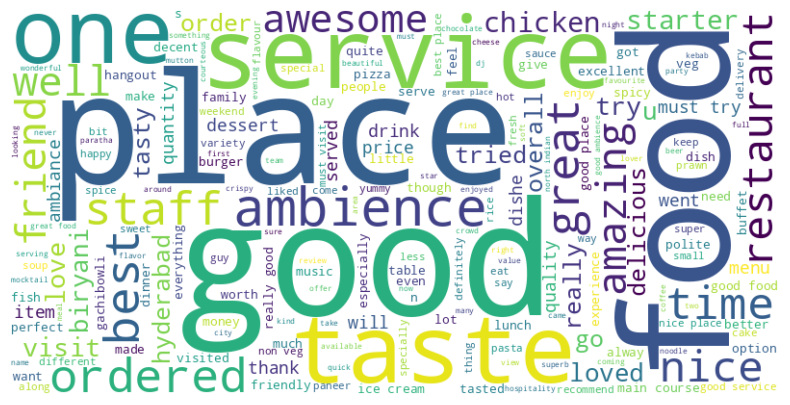

In [223]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

def plot_word_cloud(text):
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(' '.join(text))
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off")
    plt.show()

plot_word_cloud(df[df['label'] == 'positive']['review'])

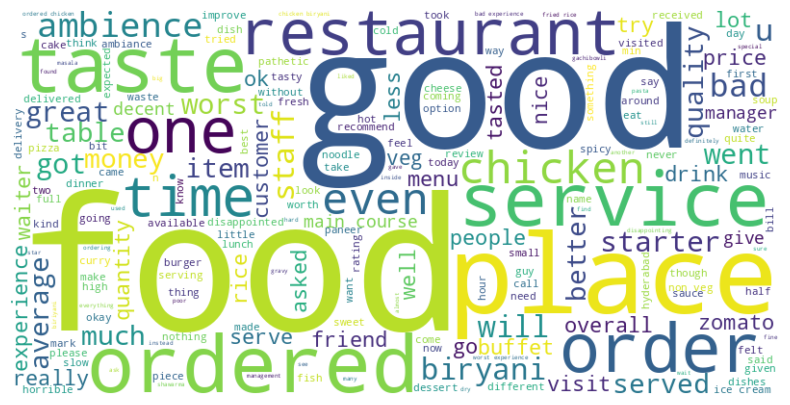

In [224]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

def plot_word_cloud(text):
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(' '.join(text))
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off")
    plt.show()

plot_word_cloud(df[df['label'] == 'negative']['review'])

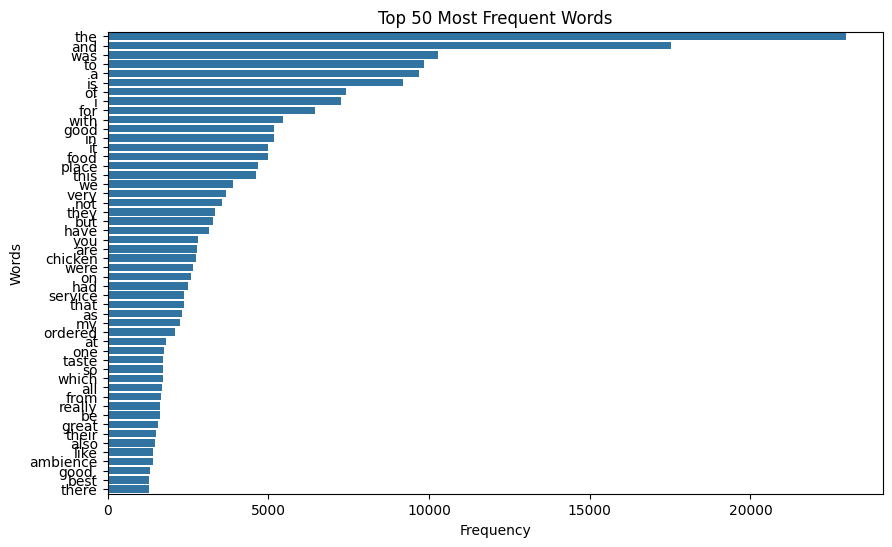

In [225]:

def plot_top_n_words(df, n=20):
    """Plot the top N most frequent words in the dataset."""
    # Flatten all words in the content column
    words = ' '.join(df['review']).split()

    # Get the top N most common words
    counter = Counter(words)
    most_common_words = counter.most_common(n)

    # Split the words and their counts for plotting
    words, counts = zip(*most_common_words)

    # Plot the top N words
    plt.figure(figsize=(10, 6))
    sns.barplot(x=list(counts), y=list(words))
    plt.title(f'Top {n} Most Frequent Words')
    plt.xlabel('Frequency')
    plt.ylabel('Words')
    plt.show()

# Example usage
plot_top_n_words(df, n=50)



In [226]:
import matplotlib.pyplot as plt

def plot_top_n_words_by_category(df, n=20, start=0):
    """Plot top N most frequent words with stacked sentiment categories."""

    # Flatten words and count occurrences by sentiment
    word_category_counts = {}

    for idx, row in df.iterrows():
        words = row['review'].split()
        category = row['label']

        for word in words:
            if word not in word_category_counts:
                word_category_counts[word] = {
                    'negative': 0,
                    'positive': 0
                }

            # Increment count
            word_category_counts[word][category] += 1

    # Total frequency of each word
    total_word_counts = {
        word: sum(counts.values())
        for word, counts in word_category_counts.items()
    }

    # Get top N words
    most_common_words = sorted(
        total_word_counts.items(),
        key=lambda x: x[1],
        reverse=True
    )[start:start+n]

    top_words = [word for word, _ in most_common_words]

    # Prepare data
    negative_counts = [
        word_category_counts[word]['negative']
        for word in top_words
    ]

    positive_counts = [
        word_category_counts[word]['positive']
        for word in top_words
    ]

    # Plot
    plt.figure(figsize=(12, 8))
    bar_width = 0.75

    plt.barh(
        top_words,
        negative_counts,
        label='Negative',
        height=bar_width
    )

    plt.barh(
        top_words,
        positive_counts,
        left=negative_counts,
        label='Positive',
        height=bar_width
    )

    plt.xlabel('Frequency')
    plt.ylabel('Words')
    plt.title(
        f'Top {n} Most Frequent Words with Sentiment Categories'
    )

    plt.legend(title='Sentiment', loc='lower right')

    # Highest frequency at the top
    plt.gca().invert_yaxis()

    plt.tight_layout()
    plt.show()

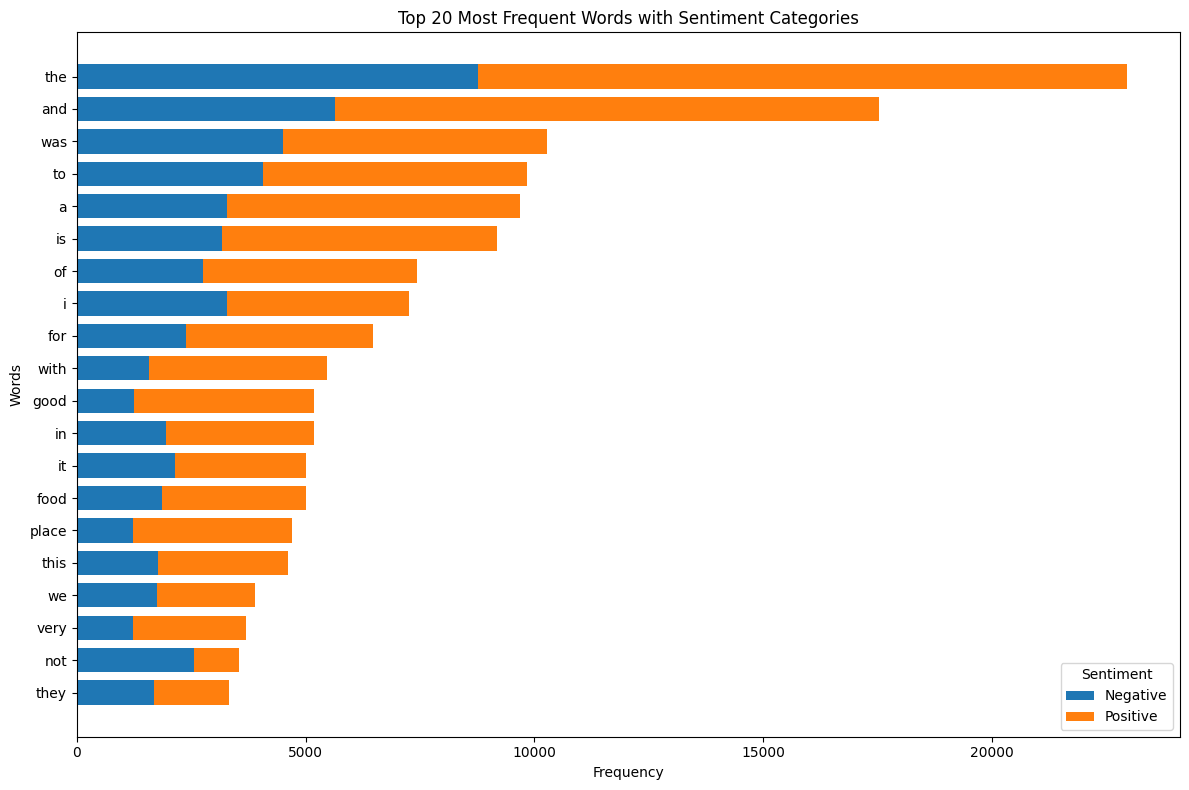

In [228]:
plot_top_n_words_by_category(df, n=20)


In [229]:
# Chỉ lấy 2 cột review và label
df_export = df[["review", "label"]].copy()

# Lưu thành file CSV
df_export.to_csv("reviews_sentiment.csv", index=False, encoding="utf-8-sig")

# Tải file về máy (Google Colab)
from google.colab import files
files.download("reviews_sentiment.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>